In [74]:
def evaluate_cut(graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v, weight in graph.weighted_edge_list():
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += weight
    return cut_value

71.0


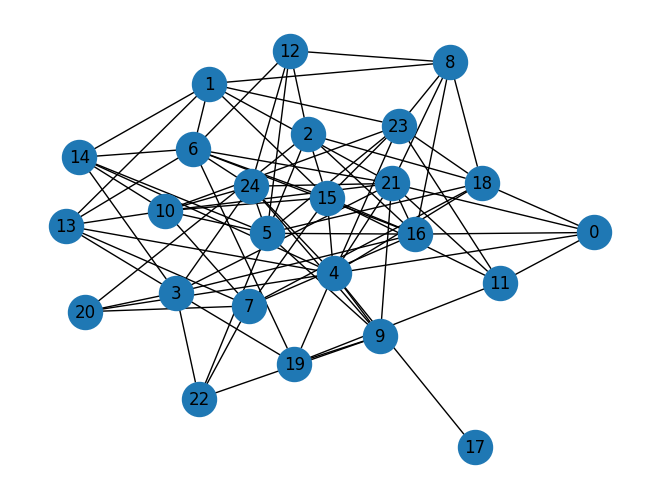

In [75]:
import numpy as np
import rustworkx as rx

def planted_maxcut_adjacency_matrix(n, p_between=0.5, p_within=0.1, seed=None):
    if seed is not None:
        np.random.seed(seed)

    adj_matrix = np.zeros((n, n))
    half = n // 2
    set_A = range(half)
    set_B = range(half, n)

    # Edges between the partitions (cut edges)
    for i in set_A:
        for j in set_B:
            if np.random.rand() < p_between:
                adj_matrix[i, j] = 1.0
                adj_matrix[j, i] = 1.0

    # Edges within the partitions (non-cut edges)
    for part in [set_A, set_B]:
        for i in part:
            for j in part:
                if i < j and np.random.rand() < p_within:
                    adj_matrix[i, j] = 1.0
                    adj_matrix[j, i] = 1.0

    planted_cut = [0 if i in set_A else 1 for i in range(n)]

    return adj_matrix, planted_cut

# Parameters
n = 25
adj_matrix, planted_cut = planted_maxcut_adjacency_matrix(n, seed=0)

# Create the rustworkx graph
graph = rx.PyGraph.from_adjacency_matrix(adj_matrix)

# Draw (optional)
from rustworkx.visualization import mpl_draw
print(evaluate_cut(graph, planted_cut))
mpl_draw(graph, node_size=600, with_labels=True)


In [76]:
import networkx as nx

graph_nx = nx.from_numpy_array(adj_matrix)
cut_value, partition = nx.algorithms.approximation.maxcut.one_exchange(graph_nx)
print("Cut value:", cut_value)

Cut value: 71


In [77]:
import matplotlib.pyplot as plt

def draw_graph_cut(G, x):
    colors = []
    for i in range(n):
        if x[i] == '0' or x[i] == 0:
            colors.append("tab:grey") 
        else:
            colors.append("tab:purple") 
    pos, default_axes = rx.spring_layout(G, seed=0), plt.axes(frameon=True)
    rx.visualization.mpl_draw(G, node_color=colors, node_size=600, alpha=0.8, pos=pos, with_labels=True)

In [78]:
# import itertools

# def maxcut_brute_force(graph):
#     n = graph.num_nodes()
#     max_value = float('-inf')
#     best_cut = None

#     # Iterate over all possible bitstrings of length n
#     for bits in itertools.product("01", repeat=n):
#         bitstring = ''.join(bits)
#         value = evaluate_cut(graph, bitstring)
#         if value > max_value:
#             max_value = value
#             best_cut = bitstring

#     return max_value, best_cut

# max_value, best_bitstring = maxcut_brute_force(graph)
# print(f"MaxCut value: {max_value}")
# print(f"Best cut bitstring: {best_bitstring}")
# draw_graph_cut(graph, best_bitstring)

In [79]:
import numpy as np
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh

L = laplacian(adj_matrix, normed=True)
# L = laplacian(adj_matrix)

# Compute eigenvectors
vals, vecs = eigh(L)

# Fiedler vector (2nd smallest eigenvalue)
fiedler = vecs[:,n-1]

# Spectral cut: assign bits based on sign
bitstring = (fiedler >= 0).astype(int)
print(bitstring)
print(evaluate_cut(graph, bitstring))
# draw_graph_cut(graph, bitstring)

[0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1]
71.0


In [80]:
for i in range(n):
    fiedler_i = vecs[:,i]

    # Spectral cut: assign bits based on sign
    bitstring_i = (fiedler_i >= 0).astype(int)
    print(vals[i], " --> ", evaluate_cut(graph, bitstring_i))

1.9984014443252818e-15  -->  0.0
0.5438082609412116  -->  29.0
0.5655340278224519  -->  32.0
0.6060500363789454  -->  35.0
0.633109777455962  -->  32.0
0.7124579203522907  -->  34.0
0.7335551316918106  -->  35.0
0.8122051324617087  -->  37.0
0.8570593505075113  -->  42.0
0.8961109338153698  -->  38.0
0.927345978064965  -->  43.0
0.9541462037536028  -->  41.0
1.0302992877506512  -->  42.0
1.0742058066235605  -->  41.0
1.0949282451690827  -->  48.0
1.1195358063574061  -->  48.0
1.1901989770070975  -->  50.0
1.2119735193913383  -->  48.0
1.2667935595106137  -->  47.0
1.3199580867807843  -->  50.0
1.363583218312761  -->  55.0
1.3853236741131623  -->  54.0
1.4141526942958773  -->  56.0
1.555652180624899  -->  59.0
1.7320121908169437  -->  71.0


In [81]:
from qiskit.quantum_info import SparsePauliOp
def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
    # Convert the graph to Pauli list.
    pauli_list = []
    for edge in list(graph.edge_list()):
        paulis = ["I"] * len(graph)
        paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

        weight = graph.get_edge_data(edge[0], edge[1])

        pauli_list.append(("".join(paulis)[::-1], weight))

    return pauli_list


max_cut_paulis = build_max_cut_paulis(graph)

cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIZIIIZ', 'IIIIIIIIIIIIIZIIIIIIIIIIZ', 'IIIIIIIIZIIIIIIIIIIIIIIIZ', 'IIIIIIZIIIIIIIIIIIIIIIIIZ', 'IIIZIIIIIIIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIIIIIZIIIIZI', 'IIIIIIIIIIIIIIIIZIIIIIIZI', 'IIIIIIIIIIIZIIIIIIIIIIIZI', 'IIIIIIIIIIZIIIIIIIIIIIIZI', 'IIIIIIIIIZIIIIIIIIIIIIIZI', 'IIIZIIIIIIIIIIIIIIIIIIIZI', 'IZIIIIIIIIIIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIIIIIIIZIIZII', 'IIIIIIIIIIIIZIIIIIIIIIZII', 'IIIIIIIIIZIIIIIIIIIIIIZII', 'IIIIIIIIZIIIIIIIIIIIIIZII', 'IIIIIIZIIIIIIIIIIIIIIIZII', 'IIIIZIIIIIIIIIIIIIIIIIZII', 'IIIIIIIIIIIZIIIIIIIIIZIII', 'IIIIIIIIIIZIIIIIIIIIIZIII', 'IIIIIIIIZIIIIIIIIIIIIZIII', 'IIIIIZIIIIIIIIIIIIIIIZIII', 'IIIIZIIIIIIIIIIIIIIIIZIII', 'IIIZIIIIIIIIIIIIIIIIIZIII', 'IIZIIIIIIIIIIIIIIIIIIZIII', 'ZIIIIIIIIIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIIIIZIIIIZIIII', 'IIIIIIIIIIIZIIIIIIIIZIIII', 'IIIIIIIIIIZIIIIIIIIIZIIII', 'IIIIIIIIIZIIIIIIIIIIZIIII', 'IIIIIIIZIIIIIIIIIIIIZIIII', 'IIIIIIZIIIIIIIIIIIIIZIIII', 'IIIIIZIIIIIIIIIIIIIIZIIII', '

In [82]:
from qiskit.circuit.library import QAOAAnsatz
from qiskit import QuantumCircuit

init_circuit = QuantumCircuit(n)
# for i, bit in enumerate(reversed(bitstring)):  # reversed due to qubit indexing
for i, bit in enumerate(bitstring):  # reversed due to qubit indexing
    if bit == 1:
        init_circuit.x(i)

reps=5
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps, initial_state=init_circuit)
circuit.measure_all()

# circuit.draw('mpl')

Initialize Params

In [83]:
initial_gamma = np.pi
initial_beta = np.pi/2
init_params = [initial_gamma, initial_beta] * reps

In [84]:
objective_func_vals = [] # Global variable

def cost_func_estimator(params, ansatz, hamiltonian, estimator):

    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost

In [85]:
# from qiskit_ibm_runtime import QiskitRuntimeService

# QiskitRuntimeService.save_account(channel="ibm_quantum", token="<MY_IBM_QUANTUM_TOKEN>", overwrite=True, set_as_default=True)
# service = QiskitRuntimeService(channel='ibm_quantum')
# backend = service.least_busy(min_num_qubits=127)
# print(backend)

In [86]:
# from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# backend = FakeManilaV2()

In [87]:
from qiskit_aer import AerSimulator

backend = AerSimulator()

In [88]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
candidate_circuit = pm.run(circuit)
# candidate_circuit.draw('mpl')

In [89]:
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize

with Session(backend=backend) as session:
    estimator = Estimator(mode=session)
    estimator.options.default_shots = 10000

    # estimator.options.dynamical_decoupling.enable = True
    # estimator.options.dynamical_decoupling.sequence_type = "XY4"
    # estimator.options.twirling.enable_gates = True
    # estimator.options.twirling.num_randomizations = "auto"

    result = minimize(
        cost_func_estimator,
        init_params,
        args=(candidate_circuit, cost_hamiltonian, estimator),
        method="COBYLA",
        tol=1e-2,
    )
    print(result)

 message: Optimization terminated successfully.
 success: True
  status: 1
     fun: -55.97600000000002
       x: [ 3.141e+00  1.570e+00  3.143e+00  1.577e+00  3.149e+00
            1.571e+00  3.142e+00  1.571e+00  3.142e+00  1.571e+00]
    nfev: 50
   maxcv: 0.0


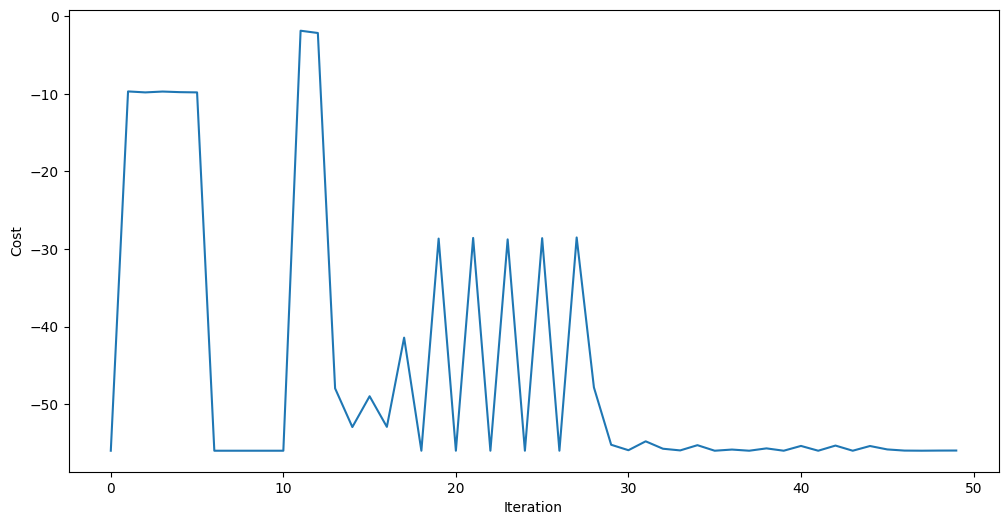

In [90]:
plt.figure(figsize=(12, 6))
plt.plot(objective_func_vals)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()

In [91]:
optimized_circuit = candidate_circuit.assign_parameters(result.x)
optimized_circuit.draw('mpl', fold=False, idle_wires=False)

In [92]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)
sampler.options.default_shots = 10000

# # Set simple error suppression/mitigation options
# sampler.options.dynamical_decoupling.enable = True
# sampler.options.dynamical_decoupling.sequence_type = "XY4"
# sampler.options.twirling.enable_gates = True
# sampler.options.twirling.num_randomizations = "auto"

pub= (optimized_circuit, )
job = sampler.run([pub], shots=int(1e4))
counts_int = job.result()[0].data.meas.get_int_counts()
counts_bin = job.result()[0].data.meas.get_counts()
shots = sum(counts_int.values())
final_distribution_int = {key: val/shots for key, val in counts_int.items()}
final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}
print(final_distribution_int)

{33550336: 0.9973, 33550344: 0.0003, 33550338: 0.0001, 33550368: 0.0002, 16773120: 0.0003, 29356032: 0.0001, 32501760: 0.0003, 33542144: 0.0002, 33550592: 0.0001, 33550352: 0.0001, 33550848: 0.0004, 33533952: 0.0002, 33550340: 0.0002, 33551360: 0.0002}


In [93]:
# auxiliary functions to sample most likely bitstring
def to_bitstring(integer, num_bits):
    result = np.binary_repr(integer, width=num_bits)
    return [int(digit) for digit in result]

keys = list(final_distribution_int.keys())
values = list(final_distribution_int.values())
most_likely = keys[np.argmax(np.abs(values))]
most_likely_bitstring = to_bitstring(most_likely, len(graph))
most_likely_bitstring.reverse()

print("Result bitstring:", most_likely_bitstring)

Result bitstring: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [94]:
# import matplotlib.pyplot as plt
# import matplotlib

# matplotlib.rcParams.update({"font.size": 10})
# final_bits = final_distribution_bin
# values = np.abs(list(final_bits.values()))
# top_4_values = sorted(values, reverse=True)[:4]
# positions = []
# for value in top_4_values:
#     positions.append(np.where(values == value)[0])
# fig = plt.figure(figsize=(11, 6))
# ax = fig.add_subplot(1, 1, 1)
# plt.xticks(rotation=45)
# plt.title("Result Distribution")
# plt.xlabel("Bitstrings (reversed)")
# plt.ylabel("Probability")
# ax.bar(list(final_bits.keys()), list(final_bits.values()), color="tab:grey")
# for p in positions:
#     ax.get_children()[int(p)].set_color("tab:purple")
# plt.show()

Cut value = 71.0


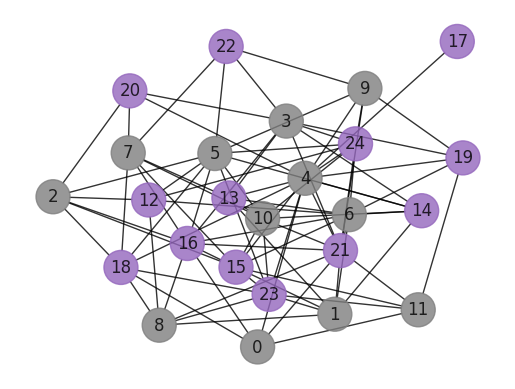

In [95]:
print(f"Cut value = {evaluate_cut(graph, most_likely_bitstring)}")
draw_graph_cut(graph, most_likely_bitstring)